# DME Circuit
Note: DME($\pi/2$) is equivalent to a SWAP gate.

## Circuit draw
Draw DME($\phi$) circuit. Note that the phase of the ZZ gate is $\phi/2$, and the duration to evolve the ZZ can be found by $\phi/2 = t\omega$.

<>:8: SyntaxWarning: invalid escape sequence '\p'
<>:8: SyntaxWarning: invalid escape sequence '\p'
C:\Users\Admin\AppData\Local\Temp\ipykernel_6296\3439873749.py:8: SyntaxWarning: invalid escape sequence '\p'
  phi = Parameter('\phi/2')


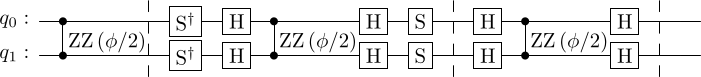

In [30]:
from qiskit import QuantumCircuit
from qiskit.circuit import Parameter
from qiskit.circuit.library import RZZGate
from qiskit.circuit import Gate

# Create a parameter for the angle
phi = Parameter('t')
phi = Parameter('\phi/2')

# Create a quantum circuit with two qubits
qc = QuantumCircuit(2)

# ZZ gate with the symbolic parameter t
qc.append(RZZGate(phi), [0, 1])
qc.barrier()

# YY gate
qc.sdg(0)
qc.sdg(1)
qc.h(0)
qc.h(1)
qc.append(RZZGate(phi), [0, 1])
qc.h(0)
qc.h(1)
qc.s(0)
qc.s(1)

qc.barrier()

# XX gate
qc.h(0)
qc.h(1)
qc.append(RZZGate(phi), [0, 1])
qc.h(0)
qc.h(1)

qc.barrier()

# Draw the circuit with the parameter t
qc.draw(output='latex', style="bw")


## Check using the dme function
The dme function can be accessed by importing `from functions.dme import *`. It takes numpy arrays for data and instruction qubit, phase of evolution, and number of iteration, apply the channel, and output the data density matrix.

In the following code, the phase $\phi$ of the DME evolution is set to be $\pi/2$. As noted above, this is a SWAP gate. 
The data and instruction state are randomly created. DME is performed on the two qubits, and we expect the data qubit to be swapped with the instruction qubit.

In [31]:
import sys
sys.path.append('..')
from functions.dme import *
import numpy as np

phi = np.pi/2
M = 1

psi0 = np.random.rand(2) + 1j * np.random.rand(2)
psi0 /= np.linalg.norm(psi0)
psi0 = psi0[np.newaxis].T
data = psi0@psi0.conj().T
print(f'Initial data qubit:\n{data}')

psi0 = np.random.rand(2) + 1j * np.random.rand(2)
psi0 /= np.linalg.norm(psi0)
psi0 = psi0[np.newaxis].T
instruction = psi0@psi0.conj().T
print(f'Initial instruction qubit:\n{instruction}')

print(f'Data qubit after DME:\n{dme_channel(data,instruction,phi,M)[0]}')

Initial data qubit:
[[0.35485131+0.j        0.40086686-0.2612233j]
 [0.40086686+0.2612233j 0.64514869+0.j       ]]
Initial instruction qubit:
[[0.31954208+0.j         0.46219401-0.06173845j]
 [0.46219401+0.06173845j 0.68045792+0.j        ]]
Data qubit after DME:
[[0.31954208+0.j         0.46219401-0.06173845j]
 [0.46219401+0.06173845j 0.68045792+0.j        ]]


In [32]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from qutip import Qobj, spre, spost, qeye, sigmax, sigmay, sigmaz, qpt
from scipy.linalg import expm

I = np.eye(2)
X = np.array([[0, 1], [1, 0]])
Y = np.array([[0, -1j], [1j, 0]])
Z = np.array([[1, 0], [0, -1]])
H = (1/np.sqrt(2)) * np.array([[1, 1], [1, -1]])
S = np.array([[1, 0], [0, 1j]])
S_dagger = S.conj().T

II = np.kron(I, I)
XX = np.kron(X, X)
YY = np.kron(Y, Y)
ZZ = np.kron(Z, Z)


In [33]:
plt.rcParams.update({
    "figure.figsize": (10, 6),
    "text.usetex": True, # Remove this line if your code doesn't run/ take too long
    "font.family": "serif",
    "figure.dpi": 100,
    "font.size": 14
})

In [34]:
# --- Pauli basis for QPT --- #
pauli_basis = [qeye(2), sigmax(), sigmay(), sigmaz()]
op_basis = [pauli_basis, pauli_basis]
pauli_labels_2q = ['II', 'IX', 'IY', 'IZ',
                   'XI', 'XX', 'XY', 'XZ',
                   'YI', 'YX', 'YY', 'YZ',
                   'ZI', 'ZX', 'ZY', 'ZZ']
# --- Define PTM labels --- #
ptm_labels = pauli_labels_2q
# --- Ideal ZZ unitary definition --- #
def zz_unitary(theta):
    return np.diag([
        np.exp(-1j * theta / 2),
        np.exp(1j * theta / 2),
        np.exp(1j * theta / 2),
        np.exp(-1j * theta / 2)
    ])
# --- Convert unitary to PTM --- #
def unitary_to_ptm(U: Qobj):
    paulis = [qeye(2), sigmax(), sigmay(), sigmaz()]
    basis = [Qobj(np.kron(p1.full(), p2.full())) for p1 in paulis for p2 in paulis]
    T = np.zeros((16, 16), dtype=np.complex128)
    for i, Pi in enumerate(basis):
        rho_out = U * Pi * U.dag()
        for j, Pj in enumerate(basis):
            T[j, i] = (Pj.dag() * rho_out).tr() / 2
    return T 


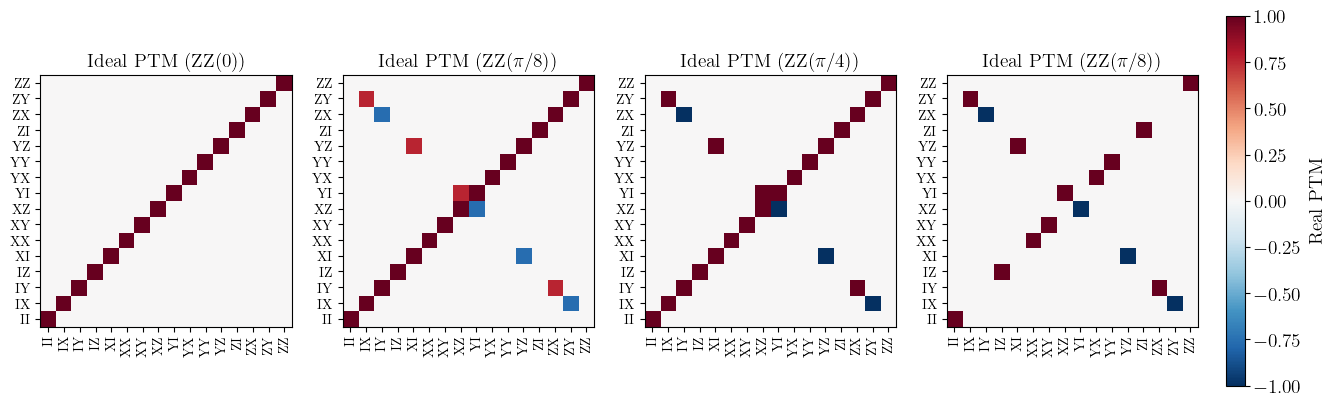

In [43]:
# --- Theta values to sweep over --- #
theta_list = [0,np.pi/8, np.pi/4, np.pi/2]
theta_name = ['0', r'$\pi/8$', r'$\pi/4$', r'$\pi/8$']

# --- Set up figure with 3 subplots --- #
fig, axes = plt.subplots(1, 4, figsize=(18, 6))

for i, theta_ZZ in enumerate(theta_list):
    U_ideal = Qobj(zz_unitary(theta_ZZ))
    ptm_ideal = unitary_to_ptm(U_ideal)

    ax = axes[i]
    cax = ax.imshow(ptm_ideal.real, cmap='RdBu_r', norm=Normalize(vmin=-1, vmax=1))
    ax.set_xticks(np.arange(16))
    ax.set_yticks(np.arange(16))
    ax.set_xticklabels(ptm_labels, rotation=90, fontsize=10)
    ax.set_yticklabels(ptm_labels, fontsize=10)
    ax.set_title(f"Ideal PTM (ZZ({theta_name[i]}))", fontsize=14)
    ax.invert_yaxis()

# Add colorbar to the right of all subplots
fig.colorbar(cax, ax=axes.ravel().tolist(), shrink=0.8, pad=0.02).set_label("Real PTM", fontsize=14)

# plt.tight_layout()
plt.show()


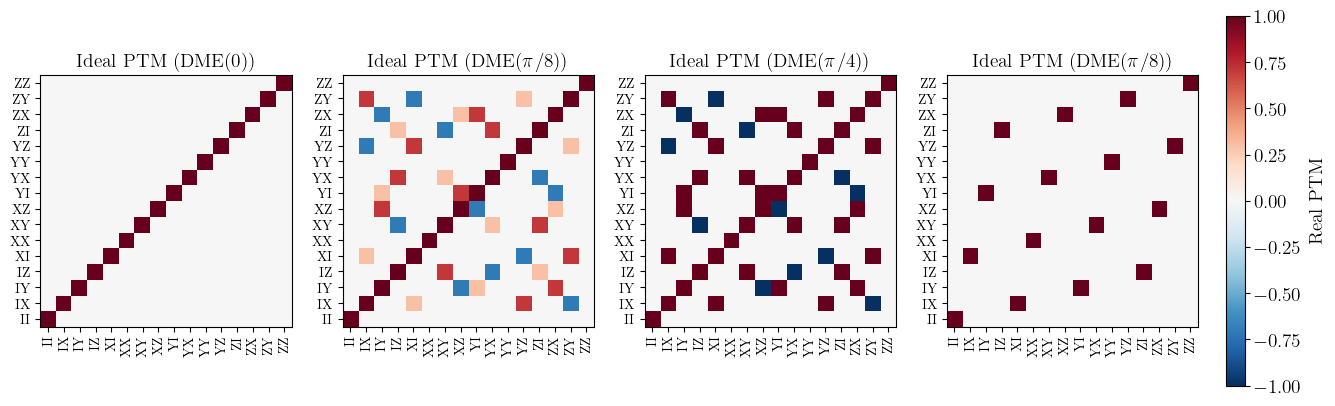

In [42]:
def dme_heisenberg(phi):
    ZZ_phi = zz_unitary(phi)
    YY_phi = np.kron(S_dagger,I) @ np.kron(H,I) @ np.kron(I,S_dagger) @ np.kron(I,H) @ zz_unitary(phi) @ np.kron(H,I) @ np.kron(S,I) @ np.kron(I,H) @ np.kron(I,S)
    XX_phi = np.kron(H,I) @ np.kron(I,H) @ zz_unitary(phi) @ np.kron(H,I) @ np.kron(I,H)
    return ZZ_phi @ YY_phi @ XX_phi

# --- Theta values to sweep over --- #
theta_list = [0, np.pi/8, np.pi/4, np.pi/2]
theta_name = ['0', r'$\pi/8$', r'$\pi/4$', r'$\pi/8$']

# --- Set up figure with 3 subplots --- #
fig, axes = plt.subplots(1, 4, figsize=(18, 6))

for i, theta_ZZ in enumerate(theta_list):
    U_ideal = Qobj(dme_heisenberg(theta_ZZ))
    ptm_ideal = unitary_to_ptm(U_ideal)

    ax = axes[i]
    cax = ax.imshow(ptm_ideal.real, cmap='RdBu_r', norm=Normalize(vmin=-1, vmax=1))
    ax.set_xticks(np.arange(16))
    ax.set_yticks(np.arange(16))
    ax.set_xticklabels(ptm_labels, rotation=90, fontsize=10)
    ax.set_yticklabels(ptm_labels, fontsize=10)
    ax.set_title(f"Ideal PTM (DME({theta_name[i]}))", fontsize=14)
    ax.invert_yaxis()

# Add colorbar to the right of all subplots
fig.colorbar(cax, ax=axes.ravel().tolist(), shrink=0.8, pad=0.02).set_label("Real PTM", fontsize=14)

# plt.tight_layout()
plt.show()



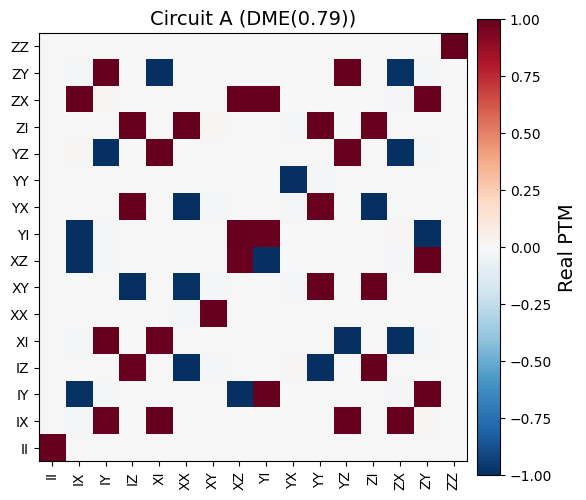

In [ ]:
def RZ(phi):
    return expm(-1j * phi * Z)

# --- Theta value --- #
theta_ZZ = 0.79

# --- Set up figure --- #
fig, ax = plt.subplots(1, 1, figsize=(6, 6))

U_ideal = Qobj(dme_heisenberg(theta_ZZ) @ np.kron(I, RZ(-0.79)))
ptm_ideal = unitary_to_ptm(U_ideal)

cax = ax.imshow(ptm_ideal.real, cmap='RdBu_r', norm=Normalize(vmin=-1, vmax=1))
ax.set_xticks(np.arange(16))
ax.set_yticks(np.arange(16))
ax.set_xticklabels(ptm_labels, rotation=90, fontsize=10)
ax.set_yticklabels(ptm_labels, fontsize=10)
ax.set_title(f"Circuit A (DME({theta_ZZ:.2f}))", fontsize=14)
ax.invert_yaxis()

fig.colorbar(cax, ax=ax, shrink=0.8, pad=0.02).set_label("Real PTM", fontsize=14)
plt.tight_layout()
plt.show()


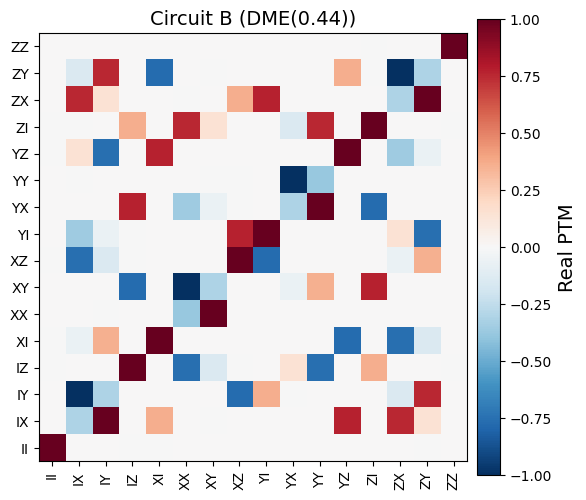

In [ ]:
# --- Theta value --- #
theta_ZZ = 0.44

# --- Set up figure --- #
fig, ax = plt.subplots(1, 1, figsize=(6, 6))

U_ideal = Qobj(dme_heisenberg(theta_ZZ) @ np.kron(I, RZ(-0.88)))
ptm_ideal = unitary_to_ptm(U_ideal)

cax = ax.imshow(ptm_ideal.real, cmap='RdBu_r', norm=Normalize(vmin=-1, vmax=1))
ax.set_xticks(np.arange(16))
ax.set_yticks(np.arange(16))
ax.set_xticklabels(ptm_labels, rotation=90, fontsize=10)
ax.set_yticklabels(ptm_labels, fontsize=10)
ax.set_title(f"Circuit B (DME({theta_ZZ:.2f}))", fontsize=14)
ax.invert_yaxis()

fig.colorbar(cax, ax=ax, shrink=0.8, pad=0.02).set_label("Real PTM", fontsize=14)
plt.tight_layout()
plt.show()
